In [1]:
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt

In [3]:
def make_graph(stock_data, revenue_data, stock):
    fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
    stock_data_specific = stock_data[stock_data.Date <= '2021-06-14']
    revenue_data_specific = revenue_data[revenue_data.Date <= '2021-04-30']
    axes[0].plot(pd.to_datetime(stock_data_specific.Date), stock_data_specific.Close.astype("float"), color="blue")
    axes[0].set_title(f"{stock} Historical Share Price")
    axes[1].plot(pd.to_datetime(revenue_data_specific.Date), revenue_data_specific.Revenue.astype("float"), color="green")
    axes[1].set_title(f"{stock} Historical Revenue")
    plt.tight_layout()
    plt.show()


In [4]:
# طلب بيانات سهم تسلا
tesla = yf.Ticker("TSLA")
tesla_data = tesla.history(period="max")
tesla_data.reset_index(inplace=True)
# عرض أول 5 صفوف للتأكد
tesla_data.head()


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


In [21]:
import warnings
# Ignore all warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [22]:
# استخدم هذا الرابط المختصر والمضمون
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"

# جلب البيانات
html_data = requests.get(url).text
soup = BeautifulSoup(html_data, 'html5lib')

# قراءة الجداول
read_html_pandas_data = pd.read_html(str(soup))
tesla_revenue = read_html_pandas_data[1]
tesla_revenue.columns = ["Date", "Revenue"]

# تنظيف البيانات
tesla_revenue["Revenue"] = tesla_revenue['Revenue'].replace(',|\$',"", regex=True)
tesla_revenue.dropna(inplace=True)
tesla_revenue = tesla_revenue[tesla_revenue['Revenue'] != ""]

# عرض النتيجة
tesla_revenue.tail()


<>:14: SyntaxWarning: invalid escape sequence '\$'
<>:14: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_7779/3686065764.py:14: SyntaxWarning: invalid escape sequence '\$'
  tesla_revenue["Revenue"] = tesla_revenue['Revenue'].replace(',|\$',"", regex=True)


,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


In [25]:
# الخطوة 3: جلب بيانات سهم GameStop
gme = yf.Ticker("GME")
gme_data = gme.history(period="max")
gme_data.reset_index(inplace=True)

# الخطوة 4: جلب بيانات أرباح GameStop
url_gme = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"
html_data_gme = requests.get(url_gme).text
soup_gme = BeautifulSoup(html_data_gme, 'html5lib')

# قراءة الجدول وتنظيفه
import io
gme_revenue = pd.read_html(io.StringIO(str(soup_gme)))[1]
gme_revenue.columns = ["Date", "Revenue"]
gme_revenue["Revenue"] = gme_revenue['Revenue'].replace(',|\$',"", regex=True)
gme_revenue.dropna(inplace=True)
gme_revenue = gme_revenue[gme_revenue['Revenue'] != ""]

# عرض النتيجة للتأكد
gme_revenue.tail()


<>:15: SyntaxWarning: invalid escape sequence '\$'
<>:15: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_7779/4048644196.py:15: SyntaxWarning: invalid escape sequence '\$'
  gme_revenue["Revenue"] = gme_revenue['Revenue'].replace(',|\$',"", regex=True)


,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


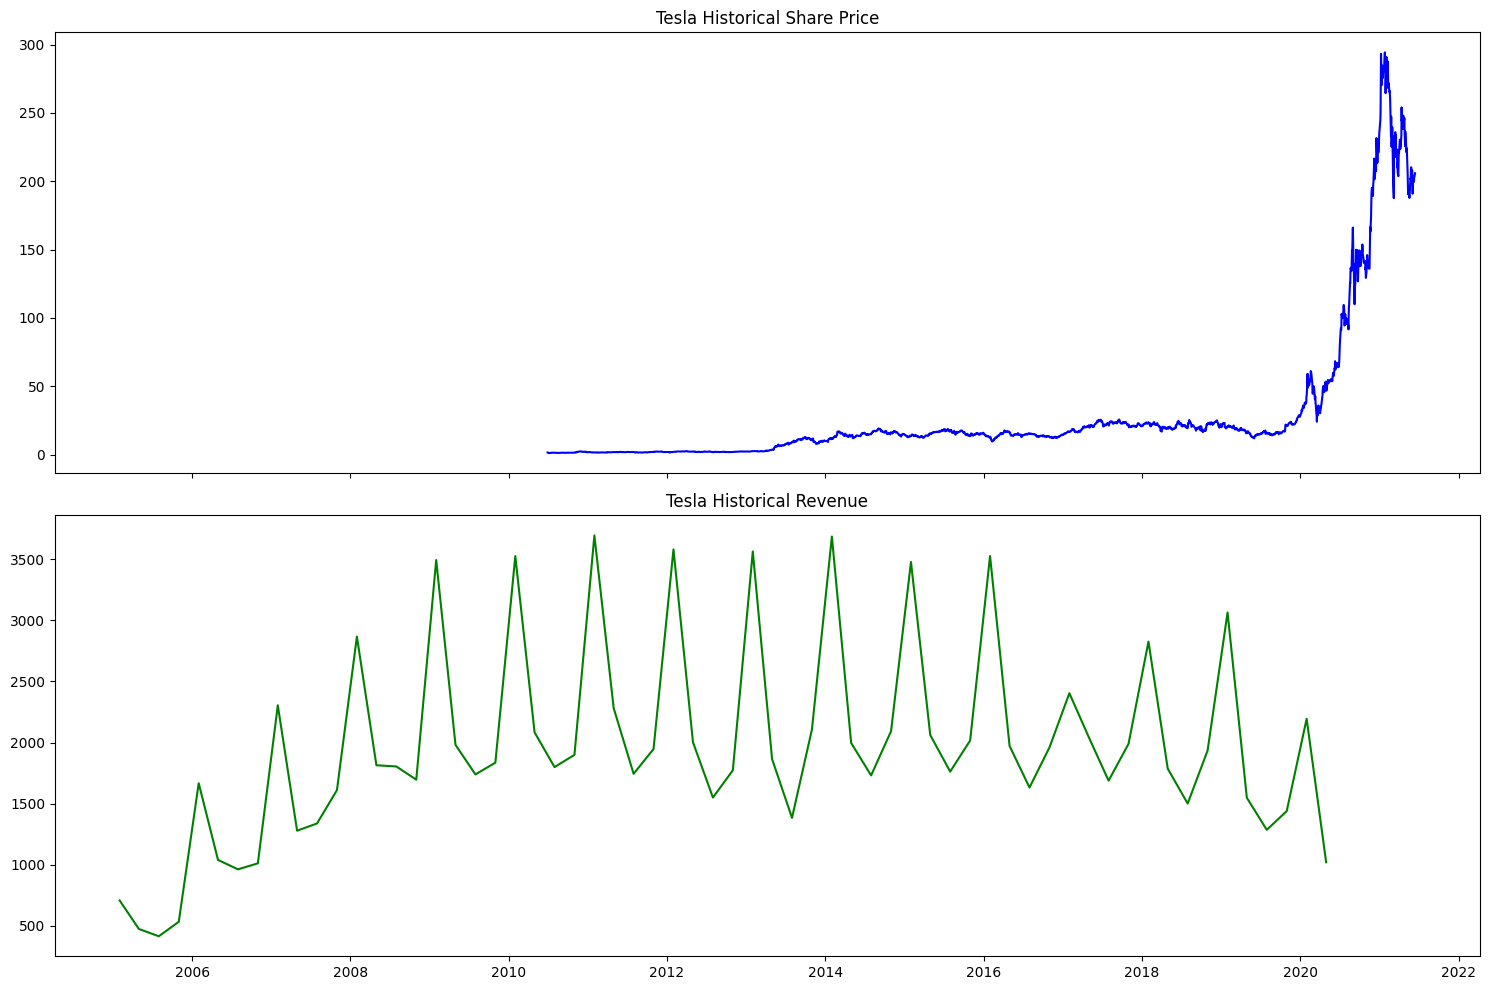

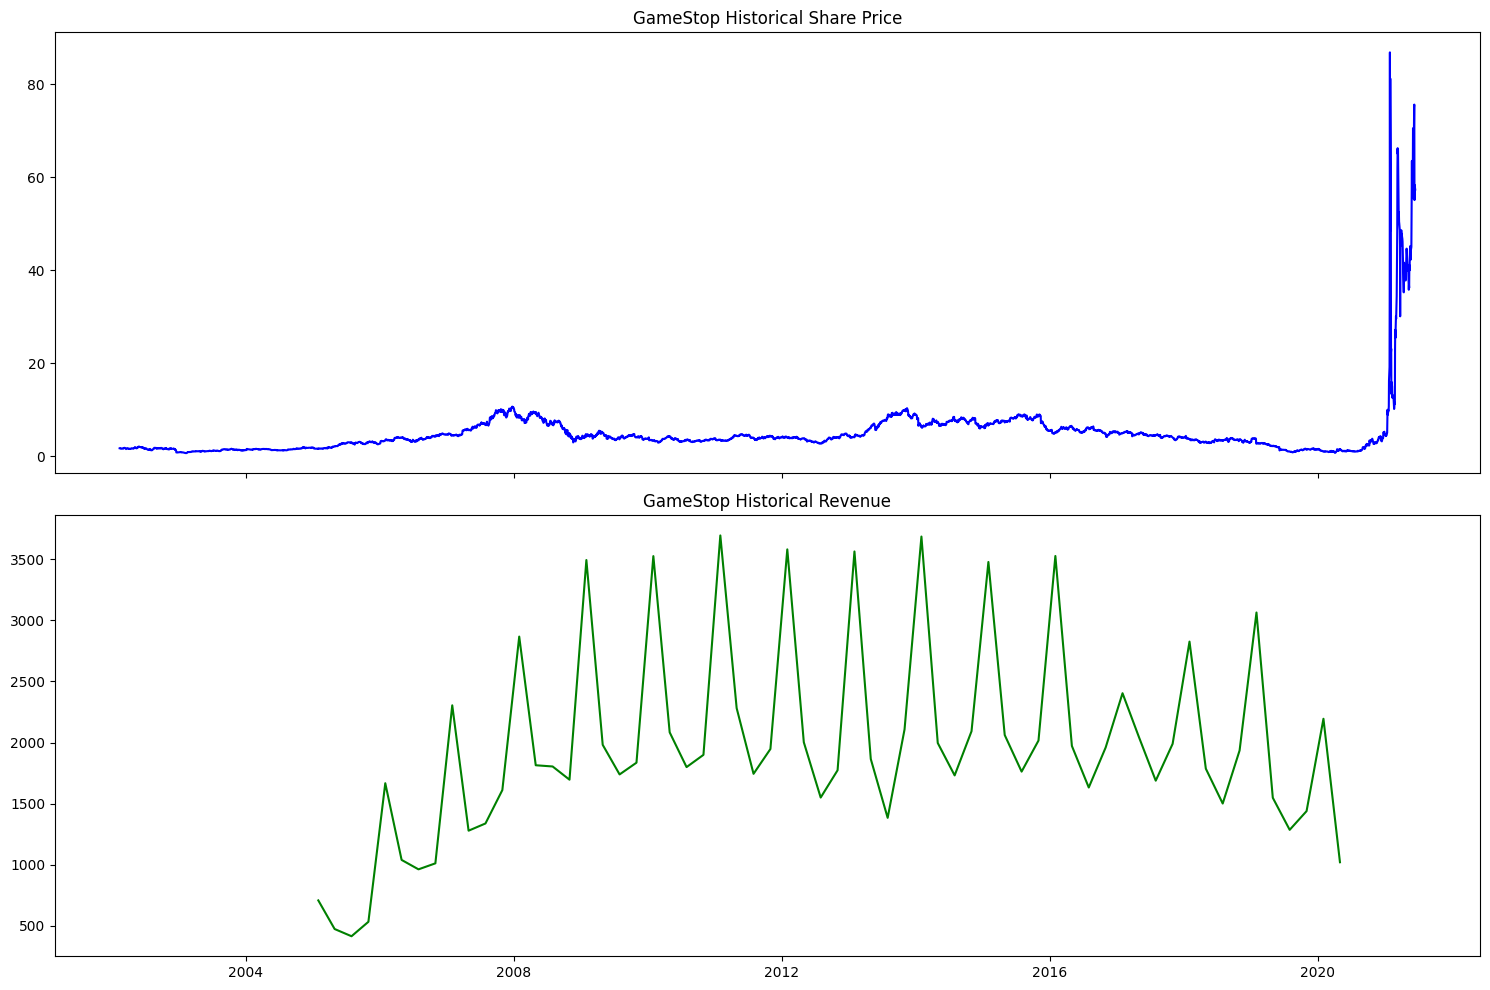

In [26]:
# رسم بيانات شركة تسلا (Tesla)
make_graph(tesla_data, tesla_revenue, 'Tesla')

# رسم بيانات شركة جيم ستوب (GameStop)
make_graph(gme_data, gme_revenue, 'GameStop')
